# Диагностика 7-дневной активации подписочного VPN

Воспроизводимый стартовый анализ полностью синтетического сервиса `ShieldRoute`. Metric contract хранится в `docs/metric_dictionary.md`, SQL-реализация — в `sql/marts/001_mart_user_activation.sql`.

## tl;dr

- В выборке **791** eligible users; 7-day activation — **55,4%**.
- В synthetic experiment: control **53,2%**, treatment **66,0%**, разница **+12.7 п.п.**
- Paid conversion: activated **71,0%**, non-activated **16,1%**. Связь описательная, не причинная.

## Context & Methods

**Решение:** определить главный провал между регистрацией, установкой приложения и регулярным VPN-использованием; оценить smart-location onboarding. Единица анализа — user.

**Каноническая активация:** приложение установлено; минимум 3 успешных VPN-сессии минимум в 2 UTC-дня; не менее 30 protected minutes в первые 7 дней.

### Key Assumptions

Порог 30 минут — портфолио-допущение. В production его нужно калибровать по retention. Все наблюдаемые эффекты и числа созданы генератором и не относятся к реальной компании.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from vpn_analytics.data_quality import validate_dataset
from vpn_analytics.metrics import user_activation_records

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "generated"
plt.style.use("seaborn-v0_8-whitegrid")

## Data

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
quality = pd.DataFrame(
    [
        {"check": result.check_name, "failures": result.failure_count, "status": result.status}
        for result in validate_dataset(DATA_DIR)
    ]
)
assert quality["failures"].sum() == 0
display(pd.Series(manifest["counts"], name="rows").to_frame())
display(quality)

,rows
devices,727
experiment_assignments,501
product_events,10185
subscriptions,800
users,800
vpn_servers,24
vpn_sessions,5305


,check,failures,status
0,unique_user_id,0,PASS
1,unique_device_id,0,PASS
2,unique_subscription_id,0,PASS
3,unique_event_id,0,PASS
4,unique_server_id,0,PASS
5,unique_vpn_session_id,0,PASS
6,devices_have_user,0,PASS
7,events_have_user_and_device,0,PASS
8,sessions_have_parents,0,PASS
9,events_not_before_registration,0,PASS


In [3]:
activation = pd.DataFrame(user_activation_records(DATA_DIR))
activation.head(3)

,user_id,registered_at,acquisition_channel,country,signup_platform,plan,subscription_status,converted_at,app_installed_at,first_successful_connection_at,...,protected_minutes_7d,traffic_gb_7d,failed_attempts_7d,total_attempts_7d,failure_rate_7d,p95_connection_time_ms,forced_disconnect_rate_7d,experiment_variant,time_to_first_value_hours,activated_7d
0,usr_000001,2026-06-01 08:48:49+00:00,referral,Other,ios,monthly,expired,NaT,2026-06-01 09:11:28.712899+00:00,2026-06-01 17:02:33.677889+00:00,...,239.273902,24.772909,2,10,0.2,3854.1,0.125000,treatment,8.229077,True
1,usr_000002,2026-01-21 11:27:28+00:00,content,KZ,android,annual,active,2026-01-27 17:42:36.288435+00:00,2026-01-22 04:43:47.426677+00:00,2026-01-22 09:38:30.160790+00:00,...,188.388962,25.985981,0,8,0.0,3960.3,0.000000,None,22.183934,True
2,usr_000003,2026-01-05 07:49:35+00:00,affiliate,US,android,monthly,expired,NaT,2026-01-06 05:26:22.203925+00:00,2026-01-06 10:46:47.754188+00:00,...,234.294294,35.409194,1,10,0.1,3137.8,0.111111,None,26.953543,True


## Results

In [4]:
funnel = pd.Series(
    {
        "Eligible users": len(activation),
        "App installed <7d": activation["app_installed_at"].notna().sum(),
        "First successful connection": activation["first_successful_connection_at"].notna().sum(),
        "3+ successful sessions": activation["successful_sessions_7d"].ge(3).sum(),
        "2+ active days": activation["active_days_7d"].ge(2).sum(),
        "30+ protected minutes": activation["protected_minutes_7d"].ge(30).sum(),
        "Activated <7d": activation["activated_7d"].sum(),
    },
    name="users",
).to_frame()
funnel["share_of_eligible"] = funnel["users"] / len(activation)
funnel

,users,share_of_eligible
Eligible users,791,1.000000
App installed <7d,719,0.908976
First successful connection,691,0.873578
3+ successful sessions,442,0.558786
2+ active days,511,0.646018
30+ protected minutes,528,0.667509
Activated <7d,438,0.553729


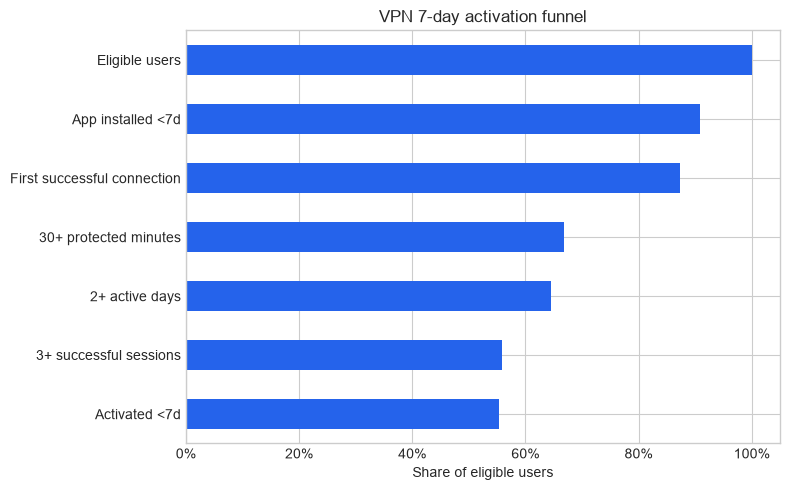

In [5]:
ax = funnel["share_of_eligible"].sort_values().plot.barh(figsize=(8, 5), color="#2563EB")
ax.set(title="VPN 7-day activation funnel", xlabel="Share of eligible users", ylabel="")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.tight_layout();

In [6]:
experiment = (
    activation.dropna(subset=["experiment_variant"])
    .groupby("experiment_variant")
    .agg(
        users=("user_id", "size"),
        activation_rate=("activated_7d", "mean"),
        mean_failure_rate=("failure_rate_7d", "mean"),
        median_user_p95_ms=("p95_connection_time_ms", "median"),
    )
)
experiment

,users,activation_rate,mean_failure_rate,median_user_p95_ms
experiment_variant,,,,
control,263,0.532319,0.173442,2813.9
treatment,238,0.659664,0.098172,2064.0


In [7]:
segments = (
    activation.groupby("signup_platform")
    .agg(
        users=("user_id", "size"),
        activation_rate=("activated_7d", "mean"),
        paid_conversion=("converted_at", lambda values: values.notna().mean()),
    )
    .sort_values("activation_rate", ascending=False)
)
segments

,users,activation_rate,paid_conversion
signup_platform,,,
macos,52,0.596154,0.423077
ios,263,0.581749,0.494297
windows,124,0.540323,0.467742
android,352,0.531250,0.448864


## Takeaways

1. Synthetic baseline activation — **55,4%**.
2. Treatment выше control на **+12.7 п.п.**; перед решением нужны SRM, confidence interval и проверка connection-quality guardrails.
3. Activated users конвертируются в оплату чаще (71,0% против 16,1%), но это не доказывает причинность.
4. Следующий шаг — retention cohorts и server-level unit economics, затем DataLens.